# 01 · Data understanding

**Owner:** Aayush · **Phase 1** of the StayScope pipeline

This notebook explores every dataset **before** any cleaning or modelling.

| Dataset | Role | File | Rows |
|---|---|---|---|
| **S** | **Main modelling dataset** (video-streaming service), and the donor for augmentation | `data/raw/train.csv` | 243,787 |
| **A** | Comparison dataset, and the augmentation target | `data/raw/netflix_customer_churn.csv` | 5,000 |
| **Old B** | Originally planned as the augmentation source. Audited here, then excluded | `data/raw/netflix_large_user_data.xlsx` | 1,000 |

**Contents**
1. Setup and loading
2. Schema
3. Data quality: missing values, duplicates, derived and redundant columns, invalid values, outliers
4. Target balance
5. Dataset S: what drives churn?
6. Dataset A: what drives churn?
7. Old Dataset B: data audit
8. Columns shared by A and S (used for matching in the augmentation study)
9. How much churn signal does each dataset hold?
10. Key findings and implications for the next phases

Nothing here modifies the data. Decisions are carried out in notebook 02 (cleaning) and notebooks 03–04
(feature mapping and augmentation). Every figure is also saved to `reports/figures/01_*.png`.

## 1. Setup and loading

In [1]:
import warnings

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

from churn import config, data, eda
from churn.plotting import CHURN, DIVERGING, NEUTRAL, RETAINED, savefig, set_style

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
set_style()
config.ensure_dirs()

TARGET, ID = config.TARGET, config.ID_COL
STATUS_PALETTE = {"Retained": RETAINED, "Churned": CHURN}
DS_COLORS = {"S": "#2BB3A3", "A": "#7C9CF5", "Old B": "#A1A1AA"}

In [2]:
s = data.load_s()
a = data.load_a()
b = data.load_b()

# Readable status column for plots; the original columns are left untouched
for df in (s, a, b):
    df["status"] = df[TARGET].map({0: "Retained", 1: "Churned"})

for name, df in [("S", s), ("A", a), ("Old B", b)]:
    print(f"Dataset {name:<5}: {len(df):>7,} rows x {df.shape[1] - 1} columns · churn {df[TARGET].mean():.1%}")

Dataset S    : 243,787 rows x 21 columns · churn 18.1%
Dataset A    :   5,000 rows x 14 columns · churn 50.3%
Dataset Old B:   1,000 rows x 16 columns · churn 53.9%


Dataset S ships with a data dictionary (`data_descriptions.csv`). `data.load_s()` renames the columns to snake_case:

In [3]:
data.load_s_descriptions()[["column", "Column_type", "Data_type", "Description"]]

,column,Column_type,Data_type,Description
0,account_age,Feature,integer,The age of the user's account in months.
1,monthly_charges,Feature,float,The amount charged to the user on a monthly ba...
2,total_charges,Feature,float,The total charges incurred by the user over th...
3,subscription_type,Feature,object,The type of subscription chosen by the user (B...
4,payment_method,Feature,string,The method of payment used by the user.
5,paperless_billing,Feature,string,Indicates whether the user has opted for paper...
6,content_type,Feature,string,The type of content preferred by the user (Mov...
7,multi_device_access,Feature,string,Indicates whether the user has access to the s...
8,device,Feature,string,"The type of device registered by the user (TV,..."
9,viewing_hours_per_week,Feature,float,The number of hours the user spends watching c...


## 2. Schema
`data.load_*` gives every dataset the same ID (`customer_id`) and target (`churned`, 0/1) names.
Columns that appear in both A and S share a name too (`subscription_type`, `device`, `favorite_genre`,
`payment_method`, `gender`).

In [4]:
print("Dataset S")
display(eda.schema_summary(s.drop(columns="status")))
print("Dataset A")
display(eda.schema_summary(a.drop(columns="status")))

Dataset S


,column,dtype,kind,unique,missing,missing_pct,example
0,customer_id,str,categorical,243787,0,0.000,CB6SXPNVZA
1,account_age,int64,numeric,119,0,0.000,20
2,monthly_charges,float64,numeric,243787,0,0.000,11.055
3,total_charges,float64,numeric,243787,0,0.000,221.104
4,subscription_type,str,categorical,3,0,0.000,Premium
5,payment_method,str,categorical,4,0,0.000,Mailed check
6,paperless_billing,str,categorical,2,0,0.000,No
7,content_type,str,categorical,3,0,0.000,Both
8,multi_device_access,str,categorical,2,0,0.000,No
9,device,str,categorical,4,0,0.000,Mobile


Dataset A


,column,dtype,kind,unique,missing,missing_pct,example
0,customer_id,str,categorical,5000,0,0.000,a9b75100-82a8-427a-a208-72f24052884a
1,age,int64,numeric,53,0,0.000,51
2,gender,str,categorical,3,0,0.000,Other
3,subscription_type,str,categorical,3,0,0.000,Basic
4,watch_hours,float64,numeric,2343,0,0.000,14.730
5,last_login_days,int64,numeric,61,0,0.000,29
6,region,str,categorical,6,0,0.000,Africa
7,device,str,categorical,5,0,0.000,TV
8,monthly_fee,float64,numeric,3,0,0.000,8.990
9,churned,int64,numeric,2,0,0.000,1


## 3. Data quality

### 3.1 Missing values and duplicates

In [5]:
pd.DataFrame({name: eda.quality_report(df.drop(columns="status"), ID)
              for name, df in [("S", s), ("A", a), ("Old B", b)]})

,S,A,Old B
rows,243787,5000,1000
columns,21,14,16
missing_cells,0,0,0
duplicate_rows,0,0,0
duplicate_ids,0,0,0


All three datasets are complete: no missing cells, no duplicate rows, no duplicate IDs. The cleaning work in
notebook 02 is about **derived/redundant columns and invalid values**, not imputation.

### 3.2 Derived and redundant columns
A *derived* column is an exact function of other columns. It adds no information and can double-count a signal.

In [6]:
checks = pd.DataFrame([
    {"dataset": "S", "column": "total_charges", "hypothesis": "= account_age x monthly_charges",
     "rows matching": ((s["total_charges"] - s["account_age"] * s["monthly_charges"]).abs() < 1e-6).mean()},
    {"dataset": "A", "column": "avg_watch_time_per_day", "hypothesis": "= watch_hours / (last_login_days + 1)",
     "rows matching": ((a["watch_hours"] / (a["last_login_days"] + 1) - a["avg_watch_time_per_day"]).abs() < 0.011).mean()},
    {"dataset": "A", "column": "monthly_fee", "hypothesis": "one value per subscription_type",
     "rows matching": float(a.groupby("subscription_type")["monthly_fee"].nunique().eq(1).all())},
])
checks["rows matching"] = checks["rows matching"].map("{:.1%}".format)
checks

,dataset,column,hypothesis,rows matching
0,S,total_charges,= account_age x monthly_charges,100.0%
1,A,avg_watch_time_per_day,= watch_hours / (last_login_days + 1),100.0%
2,A,monthly_fee,one value per subscription_type,100.0%


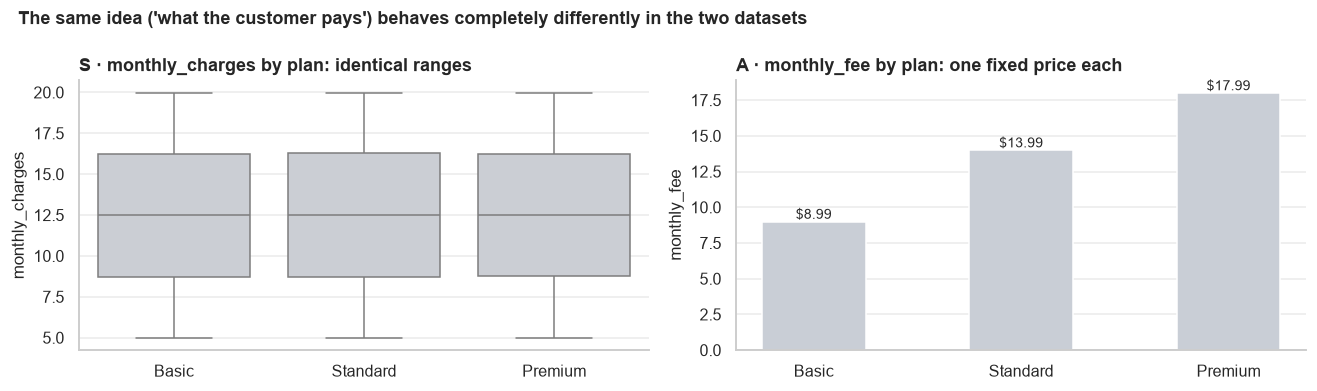

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
sns.boxplot(data=s, x="subscription_type", y="monthly_charges", order=["Basic", "Standard", "Premium"],
            color="#C9CED6", ax=axes[0], fliersize=0, linewidth=1)
axes[0].set_title("S · monthly_charges by plan: identical ranges")
axes[0].set_xlabel("")
fee = a.groupby("subscription_type")["monthly_fee"].first().reindex(["Basic", "Standard", "Premium"])
axes[1].bar(fee.index, fee.values, color="#C9CED6", width=0.5)
for i, v in enumerate(fee.values):
    axes[1].text(i, v, f"${v:.2f}", ha="center", va="bottom", fontsize=9)
axes[1].set_title("A · monthly_fee by plan: one fixed price each")
axes[1].set_ylabel("monthly_fee")
axes[1].grid(axis="x", visible=False)
fig.suptitle("The same idea ('what the customer pays') behaves completely differently in the two datasets",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
savefig(fig, "01_price_vs_plan")
plt.show()

* **S · `total_charges`** is exactly `account_age × monthly_charges`, so it's derived. **Drop it** in notebook 02.
* **S · `monthly_charges`** has the same 4.99–19.99 range on every plan, so price does not depend on plan in S.
  This is a sign of synthetic data, and it means `monthly_charges` and A's `monthly_fee` are **not
  comparable** for matching.
* **A · `avg_watch_time_per_day`** is exactly `watch_hours / (last_login_days + 1)`, so it's derived.
* **A · `monthly_fee`** is a one-to-one recoding of `subscription_type`, so it's redundant.

### 3.3 Invalid values

In [8]:
invalid = a[a["avg_watch_time_per_day"] > 24]
print(f"A · rows claiming more than 24 h of viewing per day: {len(invalid)}")
display(invalid[[ID, "watch_hours", "last_login_days", "avg_watch_time_per_day", TARGET]]
        .sort_values("avg_watch_time_per_day", ascending=False))

range_rules = {  # documented ranges from data_descriptions.csv / common sense
    "account_age": (1, None), "monthly_charges": (0, None), "viewing_hours_per_week": (0, 168),
    "avg_viewing_duration": (0, None), "content_downloads_per_month": (0, None), "user_rating": (1, 5),
    "support_tickets_per_month": (0, None), "watchlist_size": (0, None),
}
viol = {c: int((~s[c].between(lo if lo is not None else -np.inf, hi if hi is not None else np.inf)).sum())
        for c, (lo, hi) in range_rules.items()}
print("S · values outside their valid range:", viol)

A · rows claiming more than 24 h of viewing per day: 10


,customer_id,watch_hours,last_login_days,avg_watch_time_per_day,churned
2017,23e2a122-9e50-41d8-a434-c25675765f79,98.420,0,98.420,0
1219,45ea1095-e06b-4a1c-a0b7-c3671c9f006a,52.800,0,52.800,0
2564,511d9a10-669b-4283-bc6d-40c10a595b43,34.530,0,34.530,0
4792,88a98e69-9e49-4d28-98d7-1e0b1bce6138,32.880,0,32.880,0
4078,9adb0b11-3199-438c-9b3c-59dee22c6b27,32.810,0,32.810,0
4805,b906246e-44aa-441f-85c5-fc2aa946b0cb,29.550,0,29.550,0
3641,64d85f24-42f8-48b1-8675-590db42d23e5,28.660,0,28.660,0
4285,3878e4e3-2960-4b36-b25c-f90ddd01b5d8,54.530,1,27.270,0
4845,d202349e-dd45-42e7-84a9-fa604082763f,26.980,0,26.980,0
647,c350d5a0-fef7-4281-b752-42162d72bd05,25.150,0,25.150,0


S · values outside their valid range: {'account_age': 0, 'monthly_charges': 0, 'viewing_hours_per_week': 0, 'avg_viewing_duration': 0, 'content_downloads_per_month': 0, 'user_rating': 0, 'support_tickets_per_month': 0, 'watchlist_size': 0}


In A, the `+ 1` in the formula gives customers who logged in today (`last_login_days = 0`) their **entire**
`watch_hours` as a single day. That produces impossible values above 24 h/day. S has **no** out-of-range values.

### 3.4 Outliers (IQR rule, k = 1.5)

In [9]:
print("Dataset S")
display(eda.outlier_summary(s, data.S_NUMERIC))
print("Dataset A")
display(eda.outlier_summary(a, data.A_NUMERIC))

Dataset S


,column,lower,upper,n_outliers,pct,min,max,skew
0,account_age,-60.000,180.000,0,0.000,1.000,119.000,-0.000
1,monthly_charges,-2.511,27.488,0,0.000,4.990,19.990,-0.000
2,total_charges,-811.108,"2,229.573",741,0.300,4.991,"2,378.724",0.690
3,viewing_hours_per_week,-18.419,59.403,0,0.000,1.000,40.000,-0.000
4,avg_viewing_duration,-82.906,267.197,0,0.000,5.001,179.999,0.000
5,content_downloads_per_month,-25.500,74.500,0,0.000,0.000,49.000,-0.000
6,user_rating,-1.001,7.004,0,0.000,1.000,5.000,-0.000
7,support_tickets_per_month,-5.500,14.500,0,0.000,0.000,9.000,-0.000
8,watchlist_size,-12.000,36.000,0,0.000,0.000,24.000,-0.000


Dataset A


,column,lower,upper,n_outliers,pct,min,max,skew
0,age,-12.000,100.000,0,0.000,18.000,70.000,0.010
1,watch_hours,-15.701,35.069,238,4.760,0.010,110.400,2.260
2,last_login_days,-30.000,90.000,0,0.000,0.000,60.000,-0.030
3,monthly_fee,-4.510,31.490,0,0.000,8.990,17.990,-0.140
4,number_of_profiles,-1.000,7.000,0,0.000,1.000,5.000,-0.020
5,avg_watch_time_per_day,-0.805,1.635,549,10.980,0.000,98.420,15.830


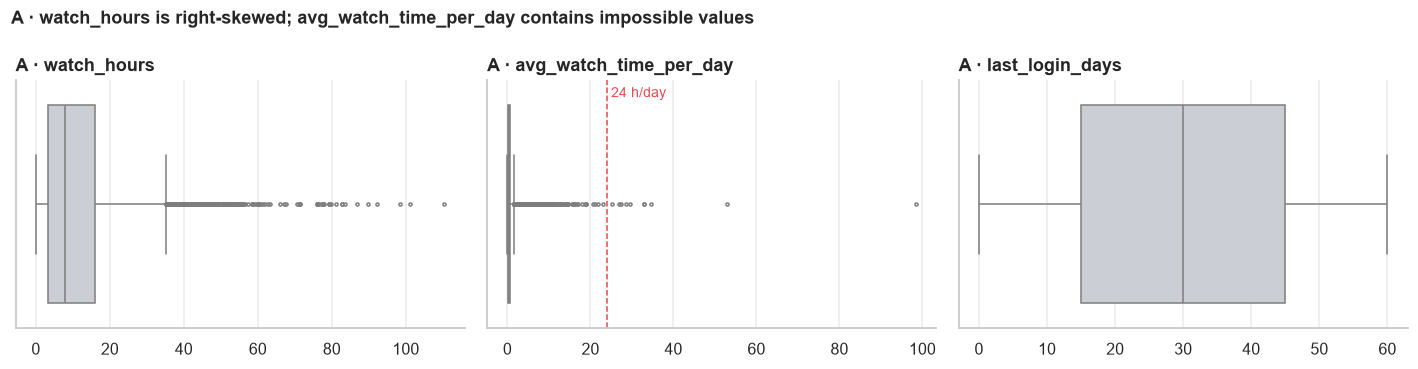

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, col in zip(axes, ["watch_hours", "avg_watch_time_per_day", "last_login_days"]):
    sns.boxplot(x=a[col], ax=ax, color="#C9CED6", fliersize=2, linewidth=1)
    ax.set_title(f"A · {col}")
    ax.set_xlabel("")
axes[1].axvline(24, color=CHURN, ls="--", lw=1)
axes[1].text(24, -0.42, " 24 h/day", color=CHURN, fontsize=9, va="bottom")
fig.suptitle("A · watch_hours is right-skewed; avg_watch_time_per_day contains impossible values",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
savefig(fig, "01_a_outliers")
plt.show()

* **S has no IQR outliers.** Every column is close to uniform within fixed bounds (account age 1–119 months,
  viewing 1–40 h/week, rating 1–5, …).
* **A · `watch_hours`** has a long right tail (skew ≈ 2.3, up to 110 h). These are plausible heavy viewers, so
  **keep** them, and log-transform for Logistic Regression.

## 4. Target balance

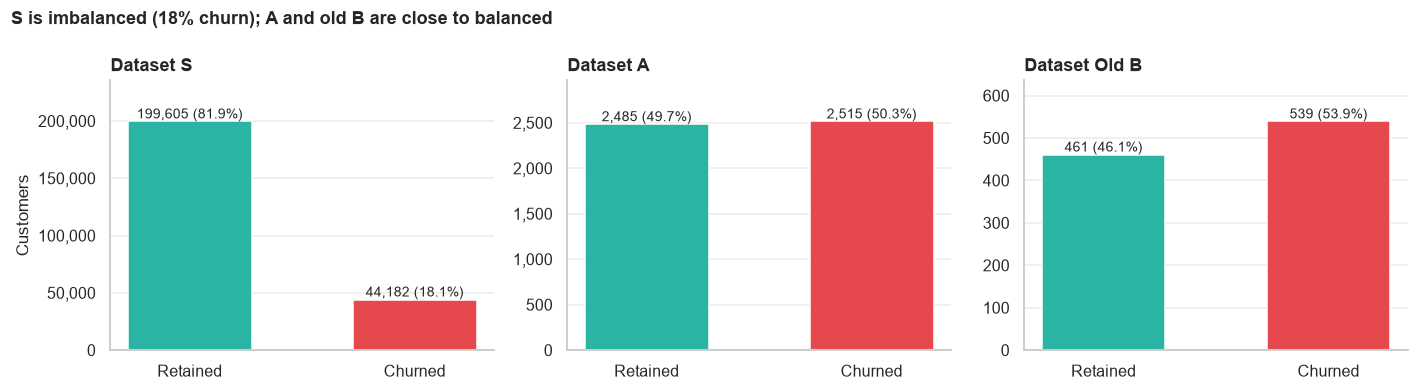

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, (name, df) in zip(axes, [("S", s), ("A", a), ("Old B", b)]):
    counts = df["status"].value_counts().reindex(["Retained", "Churned"])
    bars = ax.bar(counts.index, counts.values, color=[RETAINED, CHURN], width=0.55)
    for bar, v in zip(bars, counts.values):
        ax.text(bar.get_x() + bar.get_width() / 2, v, f"{v:,} ({v / len(df):.1%})",
                ha="center", va="bottom", fontsize=9)
    ax.set_title(f"Dataset {name}")
    ax.set_ylim(0, counts.max() * 1.18)
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x:,.0f}"))
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Customers")
fig.suptitle("S is imbalanced (18% churn); A and old B are close to balanced",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
savefig(fig, "01_target_balance")
plt.show()

In **S, only 18.1% of customers churn.** A model that always predicts "stays" would already be 81.9% accurate,
so **accuracy is misleading on S**. Notebook 05 will rely on precision, recall, F1, ROC-AUC and PR-AUC, compare
class weighting, and tune the decision threshold. A (50.3%) is balanced, so these issues barely apply to it.

## 5. Dataset S: what drives churn?

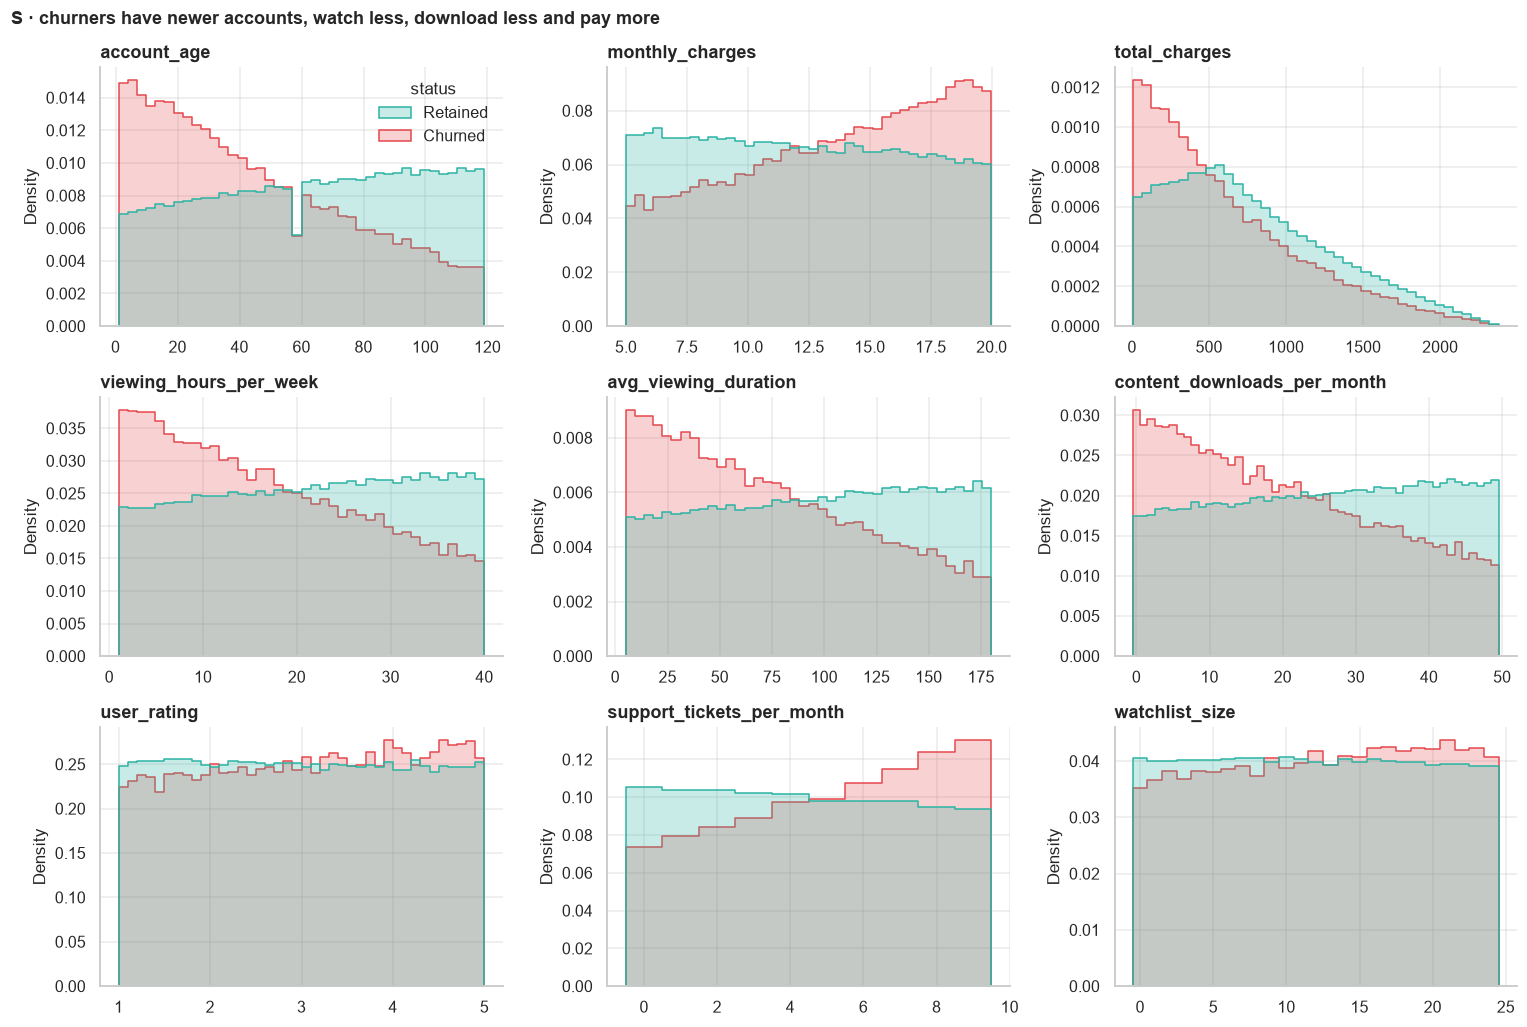

In [12]:
fig, axes = plt.subplots(3, 3, figsize=(14, 9.5))
for ax, col in zip(axes.flat, data.S_NUMERIC):
    discrete = s[col].nunique() <= 60
    sns.histplot(data=s, x=col, hue="status", palette=STATUS_PALETTE, element="step", stat="density",
                 common_norm=False, discrete=discrete, bins=40, ax=ax, legend=(col == data.S_NUMERIC[0]))
    ax.set_title(col)
    ax.set_xlabel("")
fig.suptitle("S · churners have newer accounts, watch less, download less and pay more",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
savefig(fig, "01_s_numeric_distributions")
plt.show()

In [13]:
s.groupby("status")[data.S_NUMERIC].median().T.rename_axis("median by status")

status,Churned,Retained
median by status,,
account_age,40.000,65.000
monthly_charges,13.856,12.190
total_charges,488.927,684.446
viewing_hours_per_week,16.079,21.545
avg_viewing_duration,69.773,97.505
content_downloads_per_month,19.000,26.000
user_rating,3.085,2.983
support_tickets_per_month,5.000,4.000
watchlist_size,13.000,12.000


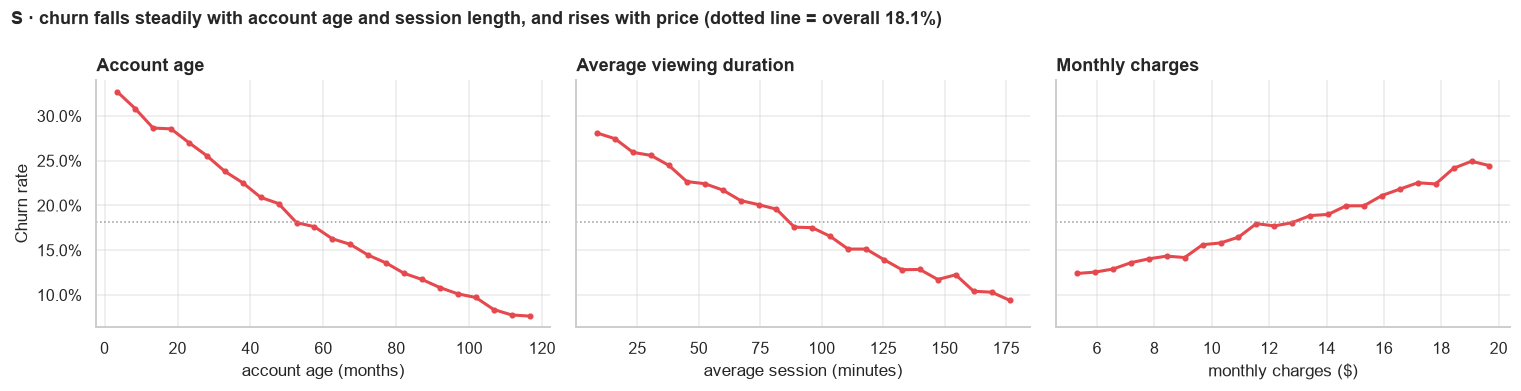

In [14]:
def churn_curve(ax, df, col, bins, xlabel, title):
    # Churn rate across equal-width bins of a numeric column, with the overall rate for reference
    g = df.groupby(pd.cut(df[col], bins), observed=True)[TARGET].agg(["mean", "size"])
    mids = [iv.mid for iv in g.index]
    ax.plot(mids, g["mean"], color=CHURN, lw=2, marker="o", ms=3)
    ax.axhline(df[TARGET].mean(), color="#999", ls=":", lw=1)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
    ax.set_xlabel(xlabel)
    ax.set_title(title)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
churn_curve(axes[0], s, "account_age", 24, "account age (months)", "Account age")
churn_curve(axes[1], s, "avg_viewing_duration", 24, "average session (minutes)", "Average viewing duration")
churn_curve(axes[2], s, "monthly_charges", 24, "monthly charges ($)", "Monthly charges")
axes[0].set_ylabel("Churn rate")
fig.suptitle("S · churn falls steadily with account age and session length, and rises with price "
             "(dotted line = overall 18.1%)", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
savefig(fig, "01_s_churn_curves")
plt.show()

Unlike A's sharp 30-day cliff (section 6), S's relationships are **smooth and gradual**. For example, churn
falls from about 33% for accounts under 6 months old to about 8% for the oldest (~10 years). That is closer to how real churn
behaves.

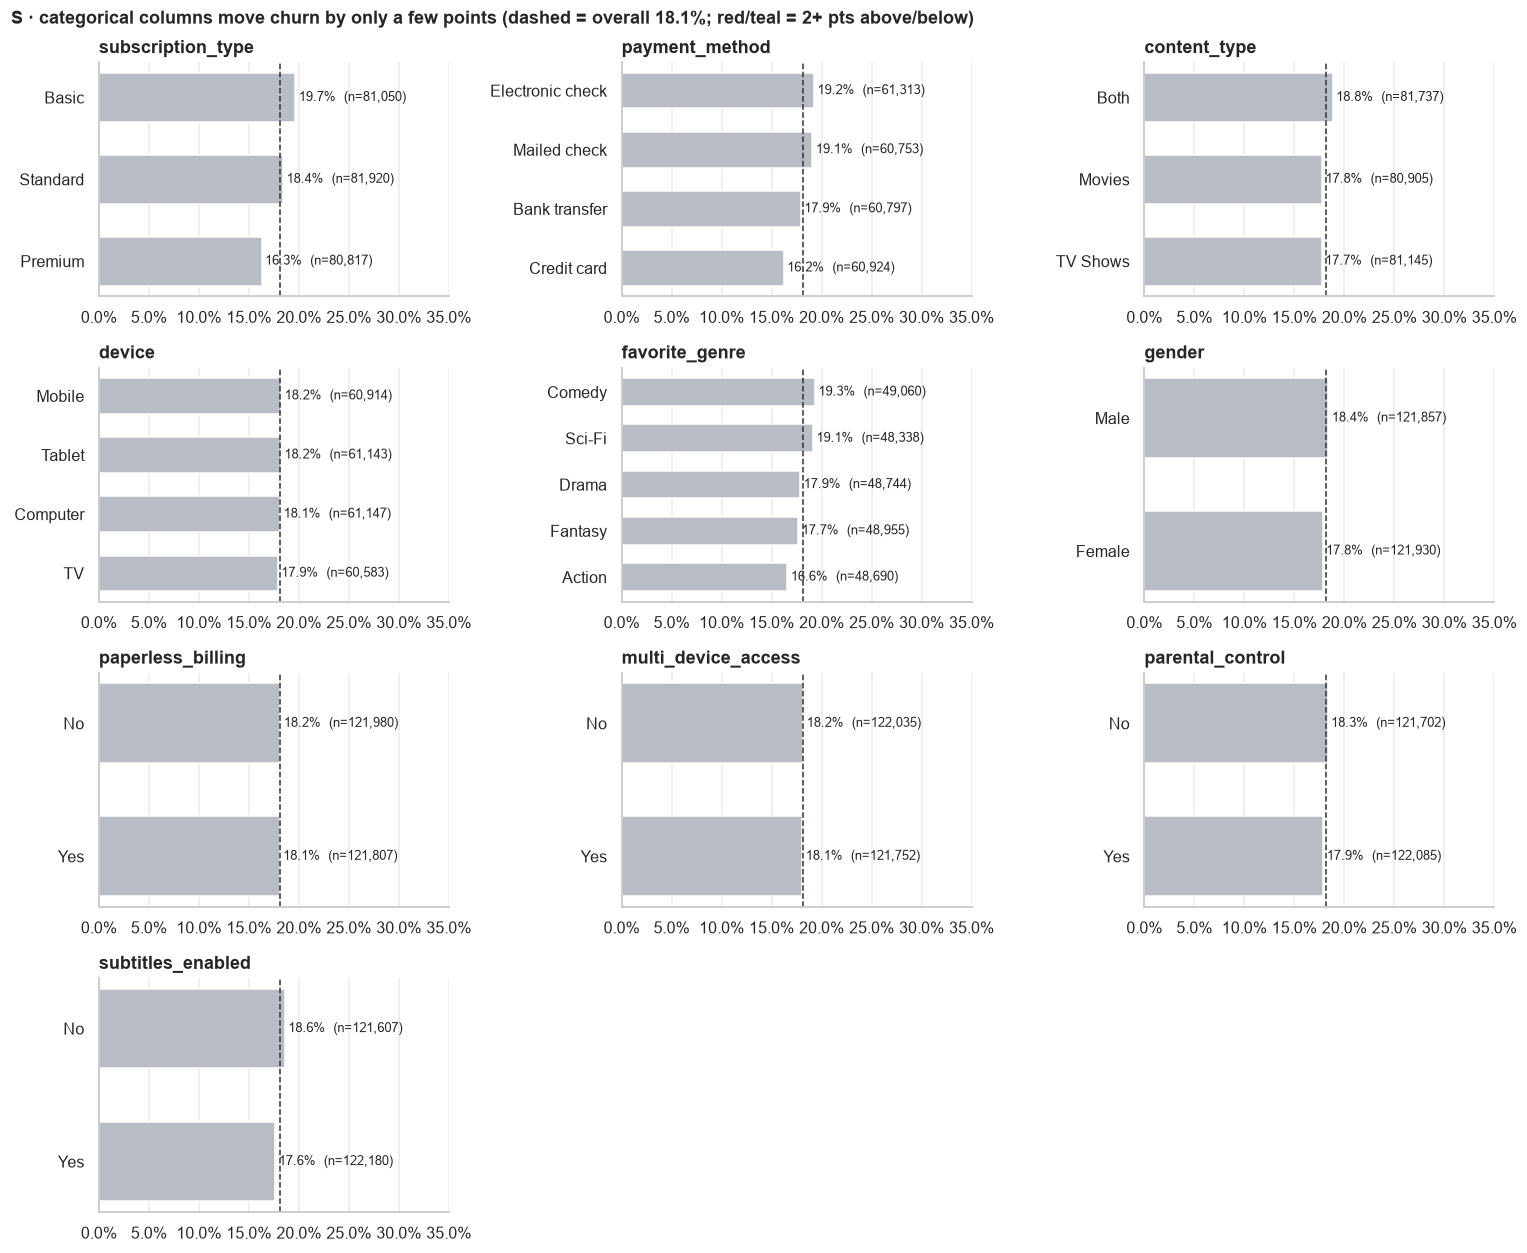

In [15]:
def plot_churn_rate_grid(df, cols, overall, title, fname, ncols=3, margin=0.02):
    # Churn rate per category; bars coloured only when they differ from the overall rate by more than `margin`
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(14, 2.9 * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, col in zip(axes, cols):
        t = eda.churn_rate_by(df, col, TARGET).sort_values("churn_rate")
        colors = [CHURN if r > overall + margin else RETAINED if r < overall - margin else "#B8BCC4"
                  for r in t["churn_rate"]]
        ax.barh(t[col].astype(str), t["churn_rate"], color=colors, height=0.6)
        xmax = max(0.35, t["churn_rate"].max() * 1.45)
        for y, (r, n) in enumerate(zip(t["churn_rate"], t["customers"])):
            ax.text(r + xmax * 0.01, y, f"{r:.1%}  (n={n:,})", va="center", fontsize=8.5)
        ax.axvline(overall, color="#333", ls="--", lw=1)
        ax.set_xlim(0, xmax)
        ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
        ax.set_title(col)
        ax.grid(axis="y", visible=False)
    for ax in axes[len(cols):]:
        ax.set_visible(False)
    fig.suptitle(title, x=0.01, ha="left", fontsize=12, fontweight="bold")
    fig.tight_layout()
    savefig(fig, fname)
    plt.show()

plot_churn_rate_grid(
    s, data.S_CATEGORICAL + data.S_BINARY, s[TARGET].mean(),
    "S · categorical columns move churn by only a few points (dashed = overall 18.1%; red/teal = 2+ pts above/below)",
    "01_s_churn_rate_by_category",
)

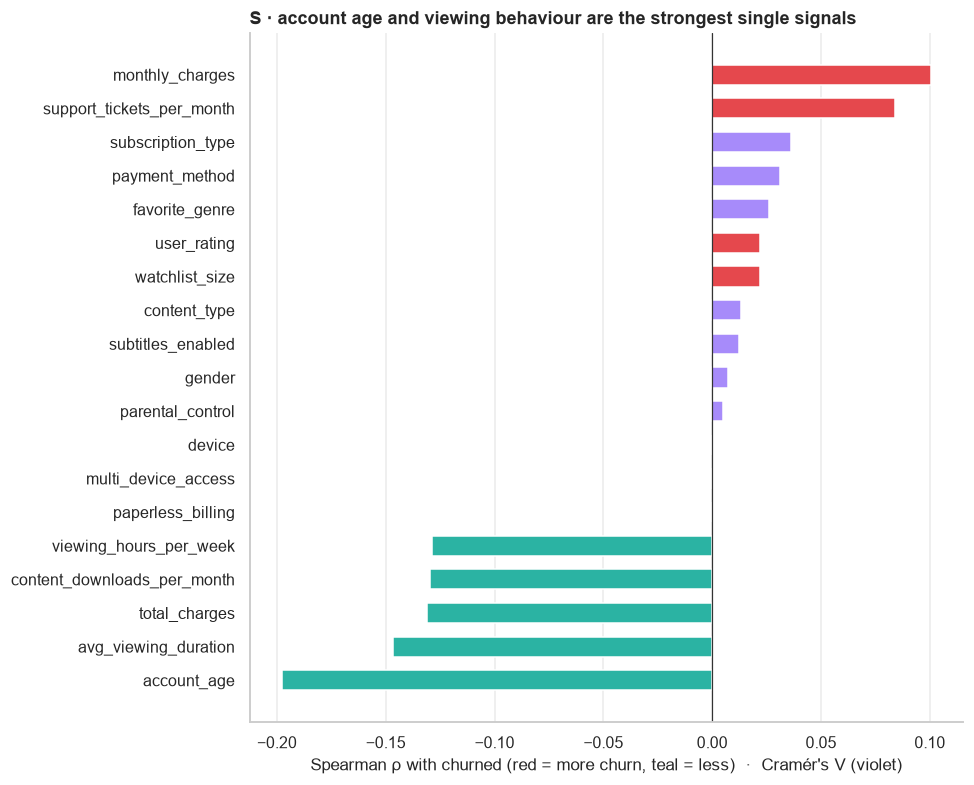

,feature,measure,value,strength
0,account_age,spearman,-0.198,0.198
1,avg_viewing_duration,spearman,-0.147,0.147
2,total_charges,spearman,-0.131,0.131
3,content_downloads_per_month,spearman,-0.130,0.130
4,viewing_hours_per_week,spearman,-0.129,0.129
5,monthly_charges,spearman,0.100,0.100
6,support_tickets_per_month,spearman,0.084,0.084
7,subscription_type,cramers_v,0.036,0.036
8,payment_method,cramers_v,0.031,0.031
9,favorite_genre,cramers_v,0.026,0.026


In [16]:
s_num = data.S_NUMERIC
s_cat = data.S_CATEGORICAL + data.S_BINARY
assoc_s = eda.target_association(s, s_num, s_cat, TARGET)

def plot_association(assoc, title, fname):
    fig, ax = plt.subplots(figsize=(9, 0.32 * len(assoc) + 1.2))
    p = assoc.sort_values("value")
    colors = ["#A78BFA" if m == "cramers_v" else (CHURN if v > 0 else RETAINED)
              for m, v in zip(p["measure"], p["value"])]
    ax.barh(p["feature"], p["value"], color=colors, height=0.6)
    ax.axvline(0, color="#333", lw=0.8)
    ax.set_xlabel("Spearman ρ with churned (red = more churn, teal = less)  ·  Cramér's V (violet)")
    ax.set_title(title)
    ax.grid(axis="y", visible=False)
    fig.tight_layout()
    savefig(fig, fname)
    plt.show()

plot_association(assoc_s, "S · account age and viewing behaviour are the strongest single signals",
                 "01_s_target_association")
assoc_s

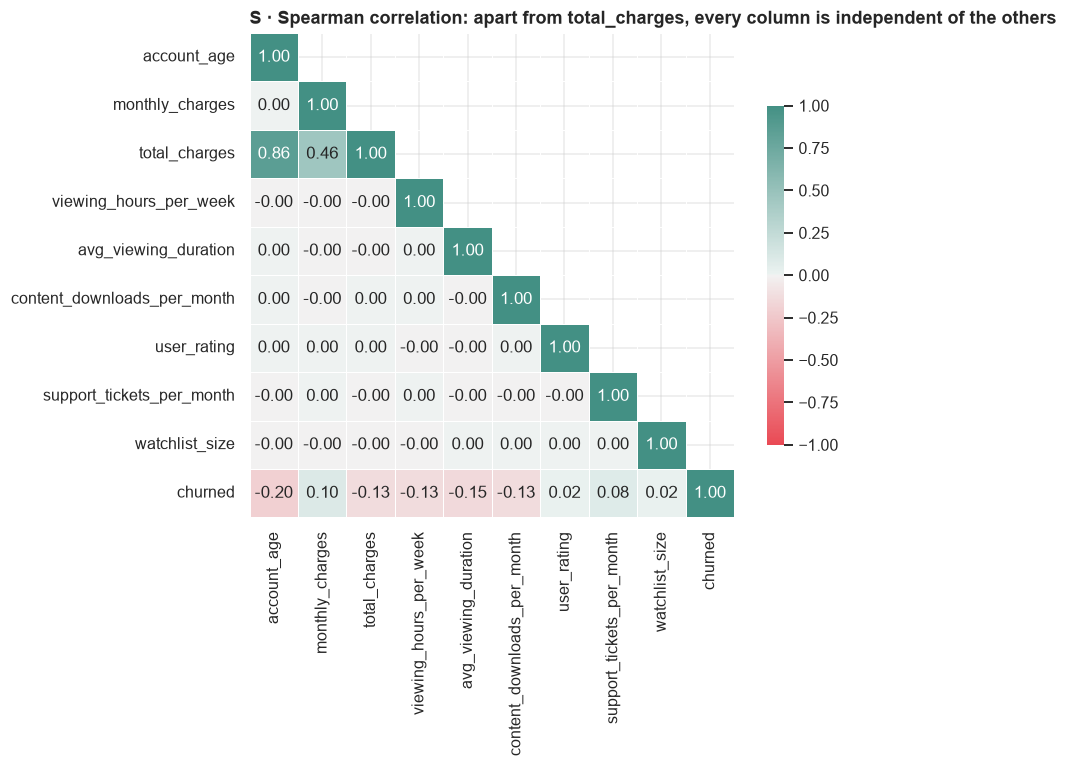

In [17]:
corr_s = s[s_num + [TARGET]].corr(method="spearman")
mask = np.triu(np.ones_like(corr_s, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(8.5, 7))
sns.heatmap(corr_s, mask=mask, cmap=DIVERGING, vmin=-1, vmax=1, annot=True, fmt=".2f",
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("S · Spearman correlation: apart from total_charges, every column is independent of the others")
fig.tight_layout()
savefig(fig, "01_s_correlation")
plt.show()

Every behavioural column in S is **uncorrelated with every other one** (|ρ| < 0.01). Only `total_charges`
correlates, because it is computed from `account_age` and `monthly_charges`. So S was generated column by
column. Each column still has its own link to churn, so S is fine for modelling. But it means **no column can
be predicted from another**, which matters a lot for the augmentation study (section 8).

## 6. Dataset A: what drives churn?

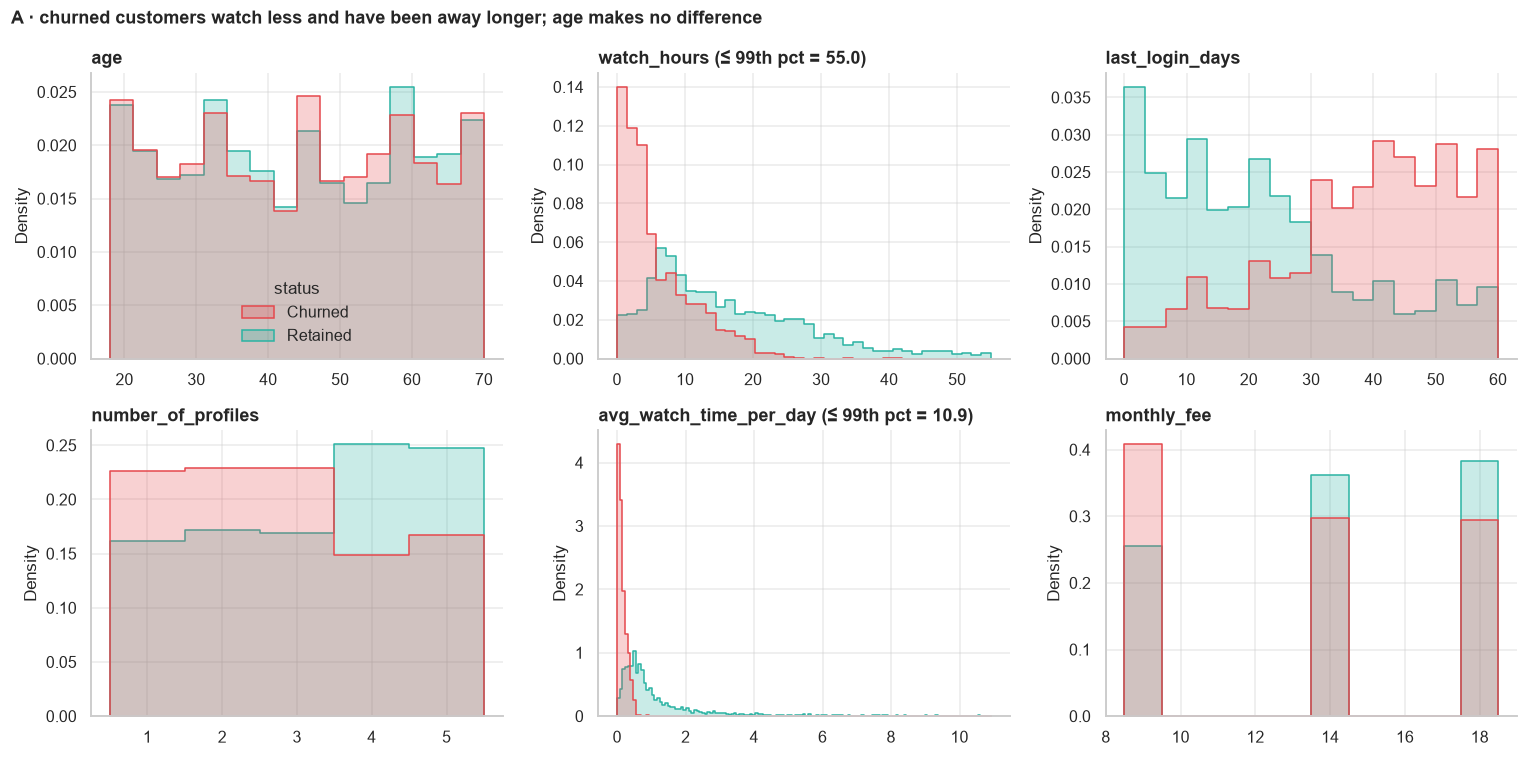

In [18]:
A_PLOT_NUMERIC = ["age", "watch_hours", "last_login_days", "number_of_profiles", "avg_watch_time_per_day", "monthly_fee"]
SKEWED = {"watch_hours", "avg_watch_time_per_day"}

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.flat, A_PLOT_NUMERIC):
    sub, title = a, col
    if col in SKEWED:
        cap = a[col].quantile(0.99)
        sub, title = a[a[col] <= cap], f"{col} (≤ 99th pct = {cap:.1f})"
    sns.histplot(data=sub, x=col, hue="status", palette=STATUS_PALETTE, element="step", stat="density",
                 common_norm=False, discrete=a[col].nunique() <= 10, ax=ax, legend=(col == "age"))
    ax.set_title(title)
    ax.set_xlabel("")
fig.suptitle("A · churned customers watch less and have been away longer; age makes no difference",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
savefig(fig, "01_a_numeric_distributions")
plt.show()

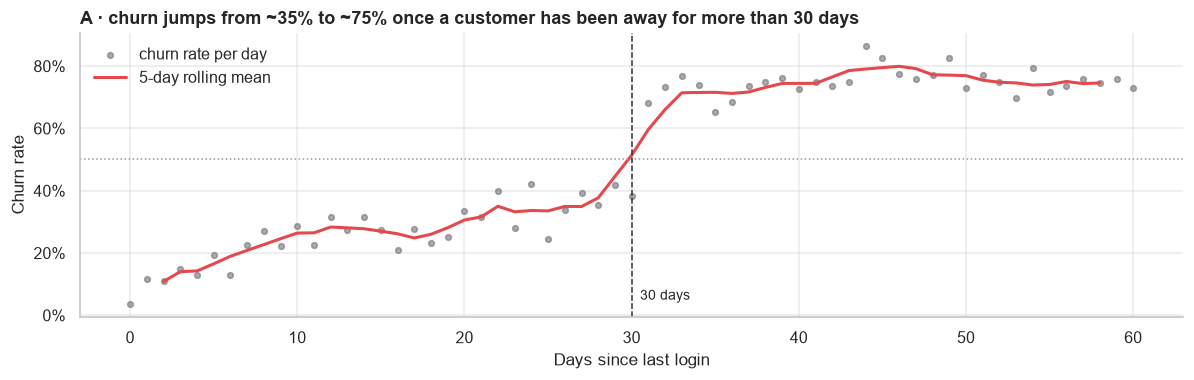

In [19]:
overall_a = a[TARGET].mean()
by_day = a.groupby("last_login_days")[TARGET].mean()

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.scatter(by_day.index, by_day.values, s=14, color=NEUTRAL, alpha=0.6, label="churn rate per day")
ax.plot(by_day.rolling(5, center=True).mean(), color=CHURN, lw=2, label="5-day rolling mean")
ax.axhline(overall_a, color="#999", ls=":", lw=1)
ax.axvline(30, color="#333", ls="--", lw=1)
ax.text(30.5, 0.05, "30 days", fontsize=9)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_xlabel("Days since last login")
ax.set_ylabel("Churn rate")
ax.set_title("A · churn jumps from ~35% to ~75% once a customer has been away for more than 30 days")
ax.legend(loc="upper left")
fig.tight_layout()
savefig(fig, "01_a_churn_by_last_login")
plt.show()

A step this sharp looks like a **rule built into A's data generator** rather than human behaviour. Together
with low watch hours, it makes A almost perfectly predictable (section 9).

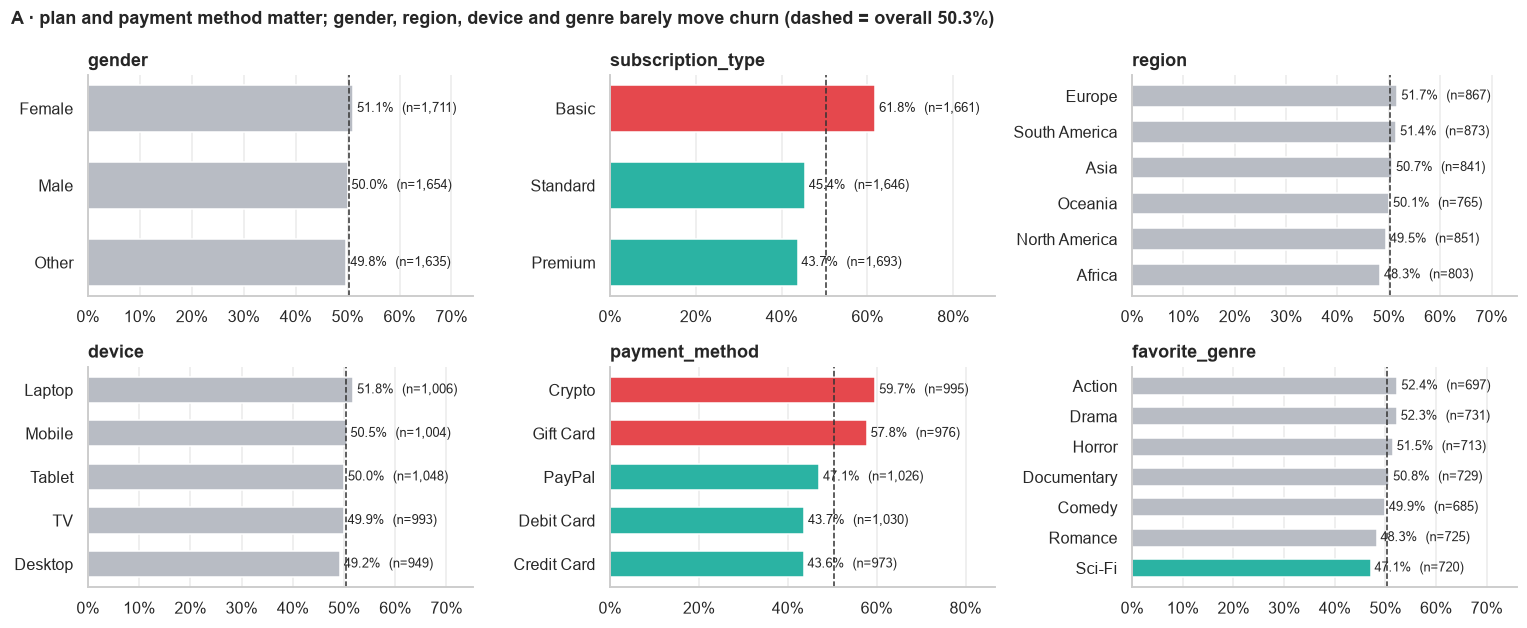

In [20]:
plot_churn_rate_grid(
    a, data.A_CATEGORICAL, overall_a,
    "A · plan and payment method matter; gender, region, device and genre barely move churn (dashed = overall 50.3%)",
    "01_a_churn_rate_by_category", margin=0.03,
)

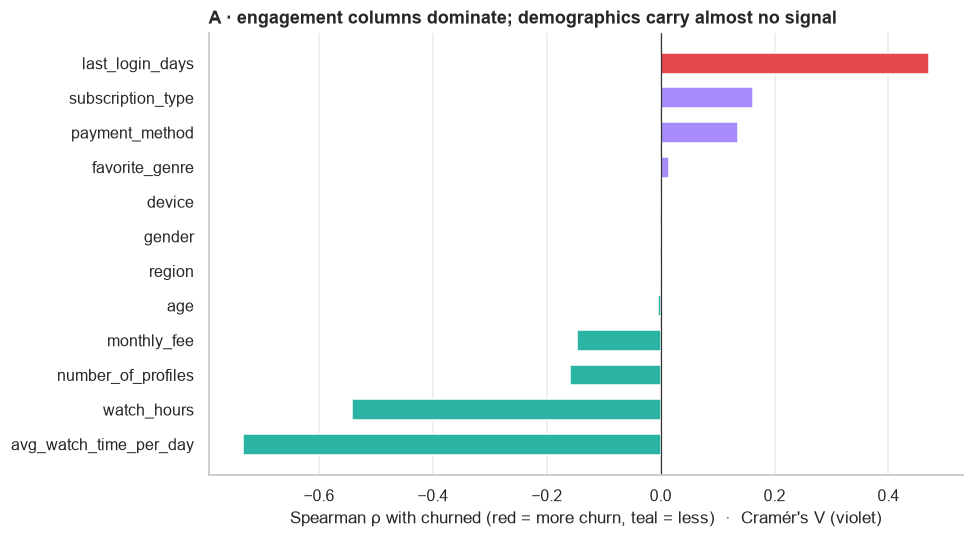

,feature,measure,value,strength
0,avg_watch_time_per_day,spearman,-0.734,0.734
1,watch_hours,spearman,-0.541,0.541
2,last_login_days,spearman,0.471,0.471
3,subscription_type,cramers_v,0.162,0.162
4,number_of_profiles,spearman,-0.159,0.159
5,monthly_fee,spearman,-0.148,0.148
6,payment_method,cramers_v,0.136,0.136
7,favorite_genre,cramers_v,0.014,0.014
8,age,spearman,-0.004,0.004
9,gender,cramers_v,0.000,0.000


In [21]:
assoc_a = eda.target_association(a, data.A_NUMERIC, data.A_CATEGORICAL, TARGET)
plot_association(assoc_a, "A · engagement columns dominate; demographics carry almost no signal",
                 "01_a_target_association")
assoc_a

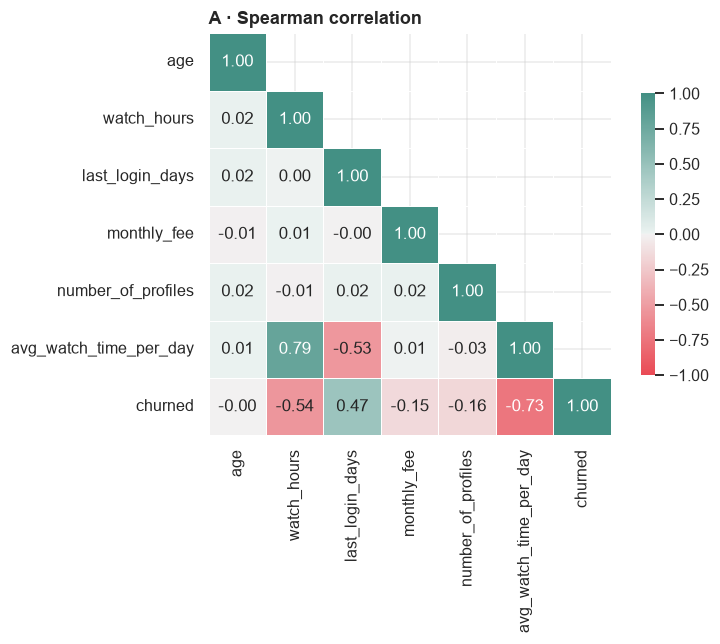

In [22]:
corr_a = a[data.A_NUMERIC + [TARGET]].corr(method="spearman")
mask = np.triu(np.ones_like(corr_a, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(corr_a, mask=mask, cmap=DIVERGING, vmin=-1, vmax=1, annot=True, fmt=".2f",
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("A · Spearman correlation")
fig.tight_layout()
savefig(fig, "01_a_correlation")
plt.show()

## 7. Old Dataset B: data audit

The original proposal planned to augment A with behavioural features from this dataset. Before doing that,
we check whether its features relate to churn **at all**.

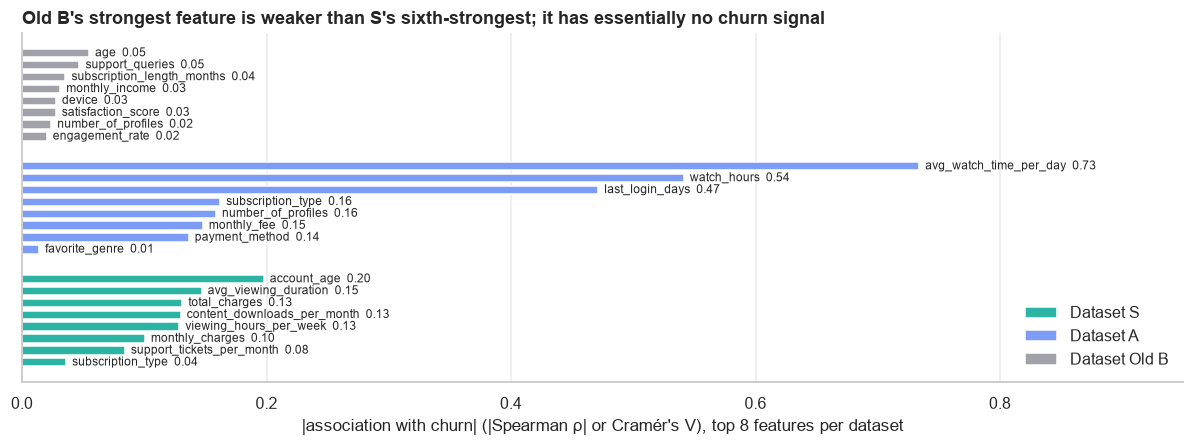

,feature,measure,value,strength
0,age,spearman,-0.055,0.055
1,support_queries,spearman,0.047,0.047
2,subscription_length_months,spearman,0.036,0.036
3,monthly_income,spearman,0.031,0.031
4,device,cramers_v,0.028,0.028
5,satisfaction_score,spearman,0.028,0.028
6,number_of_profiles,spearman,-0.024,0.024
7,engagement_rate,spearman,-0.020,0.020
8,daily_watch_time,spearman,-0.014,0.014
9,promo_offers_used,spearman,0.004,0.004


In [23]:
assoc_b = eda.target_association(b, data.B_NUMERIC, data.B_CATEGORICAL, TARGET)

fig, ax = plt.subplots(figsize=(11, 4.2))
top = pd.concat([d.assign(dataset=n).nlargest(8, "strength") for n, d in
                 [("S", assoc_s), ("A", assoc_a), ("Old B", assoc_b)]])
for i, (name, g) in enumerate(top.groupby("dataset", sort=False)):
    g = g.sort_values("strength")
    y = np.arange(len(g)) + i * 9.5
    ax.barh(y, g["strength"], color=DS_COLORS[name], height=0.7, label=f"Dataset {name}")
    for yy, (f, v) in zip(y, zip(g["feature"], g["strength"])):
        ax.text(v + 0.005, yy, f"{f}  {v:.2f}", va="center", fontsize=8)
ax.set_yticks([])
ax.set_xlim(0, 0.95)
ax.set_xlabel("|association with churn| (|Spearman ρ| or Cramér's V), top 8 features per dataset")
ax.set_title("Old B's strongest feature is weaker than S's sixth-strongest; it has essentially no churn signal")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
fig.tight_layout()
savefig(fig, "01_b_audit_association")
plt.show()
assoc_b

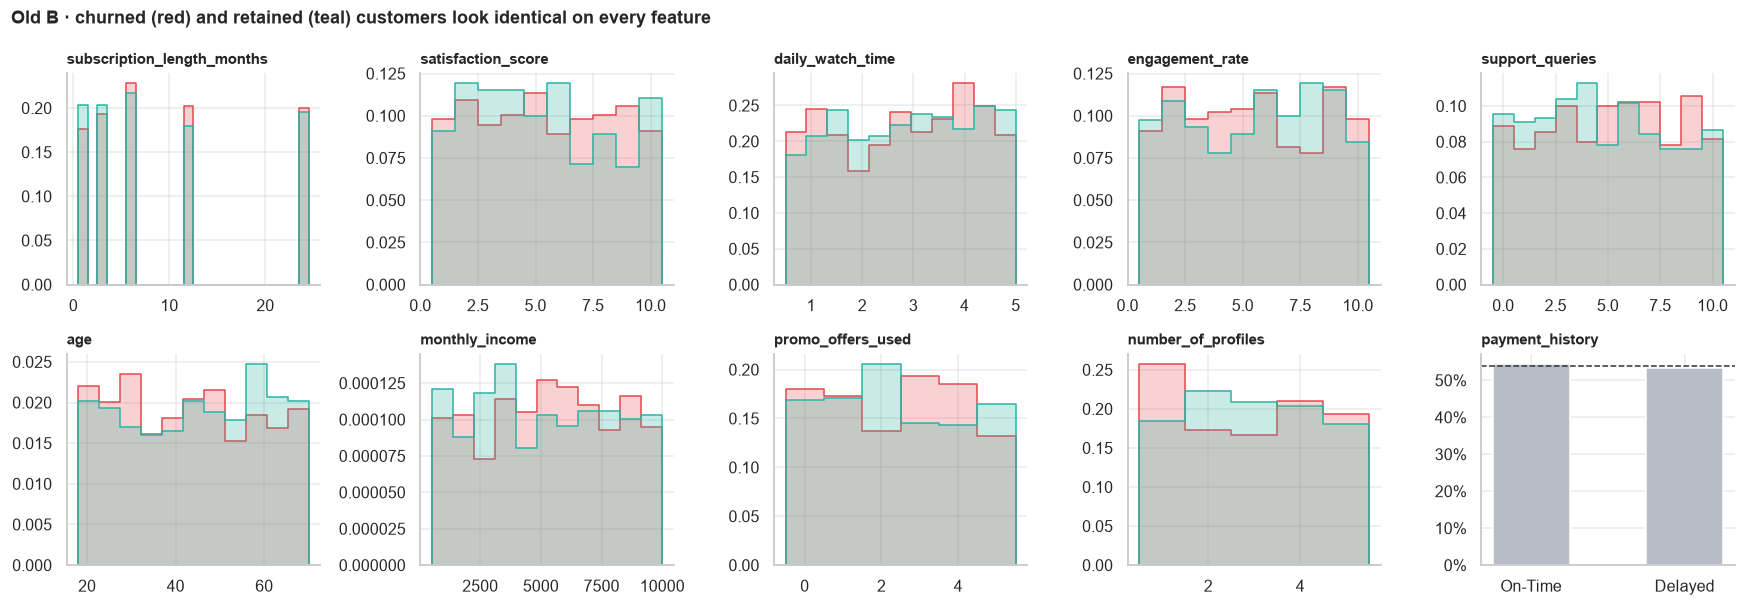

In [24]:
fig, axes = plt.subplots(2, 5, figsize=(16, 5.6))
for ax, col in zip(axes.flat, data.B_NUMERIC + ["payment_history"]):
    if col in data.B_NUMERIC:
        sns.histplot(data=b, x=col, hue="status", palette=STATUS_PALETTE, element="step", stat="density",
                     common_norm=False, discrete=b[col].nunique() <= 25, ax=ax, legend=False)
    else:
        t = eda.churn_rate_by(b, col, TARGET)
        ax.bar(t[col], t["churn_rate"], color="#B8BCC4", width=0.5)
        ax.axhline(b[TARGET].mean(), color="#333", ls="--", lw=1)
        ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
    ax.set_title(col, fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("")
fig.suptitle("Old B · churned (red) and retained (teal) customers look identical on every feature",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
savefig(fig, "01_b_audit_distributions")
plt.show()

Every old-B feature has |ρ| < 0.06 with churn, and the features are also uncorrelated with each other.
Section 9 confirms that no model can predict B's churn label. **Old B is excluded from the project.**
Transferring its features into A could only add noise. The audit itself goes into the report as a lesson:
*check a dataset's signal before you use it for augmentation.*

## 8. Columns shared by A and S

The augmentation study (notebook 04) matches each A customer to similar S customers using the columns the two
datasets share. Matching only works if those columns have **the same categories** and if they **say something
about the behaviour we want to borrow**.

In [25]:
SHARED = ["subscription_type", "device", "favorite_genre", "payment_method", "gender"]
rows = []
for col in SHARED:
    va, vs = set(a[col]), set(s[col])
    rows.append({"column": col, "only in A": ", ".join(sorted(va - vs)) or "-",
                 "only in S": ", ".join(sorted(vs - va)) or "-", "in both": ", ".join(sorted(va & vs)) or "-"})
pd.DataFrame(rows)

,column,only in A,only in S,in both
0,subscription_type,-,-,"Basic, Premium, Standard"
1,device,"Desktop, Laptop",Computer,"Mobile, TV, Tablet"
2,favorite_genre,"Documentary, Horror, Romance",Fantasy,"Action, Comedy, Drama, Sci-Fi"
3,payment_method,"Credit Card, Crypto, Debit Card, Gift Card, Pa...","Bank transfer, Credit card, Electronic check, ...",-
4,gender,Other,-,"Female, Male"


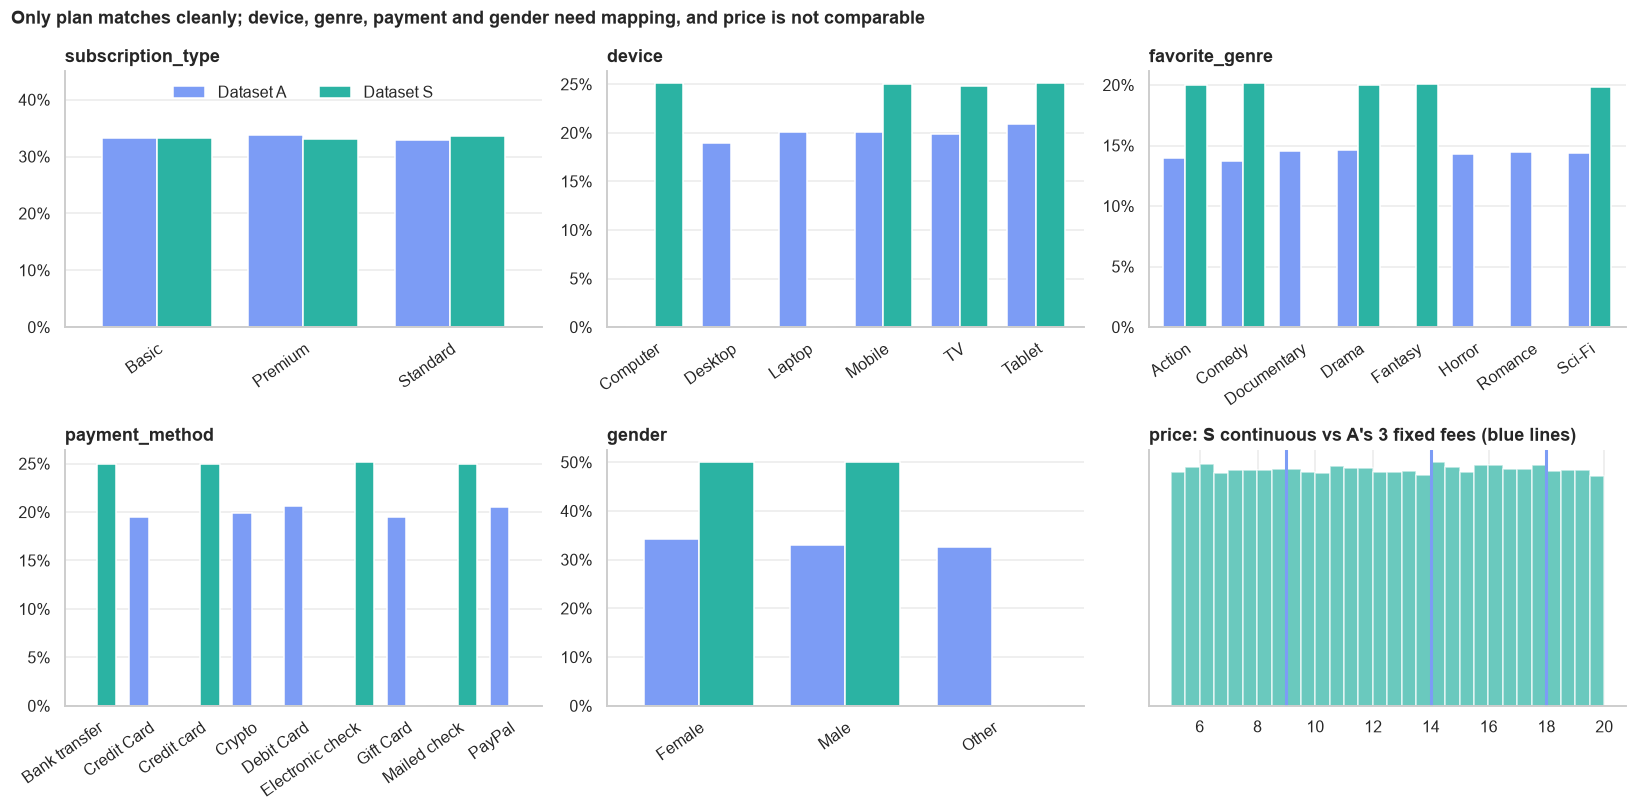

In [26]:
def shares(col):
    return pd.concat([a[col].value_counts(normalize=True).rename("Dataset A"),
                      s[col].value_counts(normalize=True).rename("Dataset S")], axis=1).fillna(0)

fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
for ax, col in zip(axes.flat, SHARED):
    shares(col).sort_index().plot.bar(ax=ax, color=[DS_COLORS["A"], DS_COLORS["S"]], width=0.75, legend=False)
    ax.tick_params(axis="x", rotation=35)
    plt.setp(ax.get_xticklabels(), ha="right", rotation_mode="anchor")
    ax.set_title(col)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
    ax.set_xlabel("")
    ax.grid(axis="x", visible=False)
axes.flat[0].legend(["Dataset A", "Dataset S"], loc="upper center", ncol=2)
axes.flat[0].set_ylim(0, 0.45)
ax = axes.flat[5]
ax.hist(s["monthly_charges"], bins=30, density=True, color=DS_COLORS["S"], alpha=0.7, label="S · monthly_charges")
for v in sorted(a["monthly_fee"].unique()):
    ax.axvline(v, color=DS_COLORS["A"], lw=2)
ax.set_title("price: S continuous vs A's 3 fixed fees (blue lines)")
ax.set_yticks([])
fig.suptitle("Only plan matches cleanly; device, genre, payment and gender need mapping, and price is not comparable",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
savefig(fig, "01_shared_columns_a_vs_s")
plt.show()

Starting point for **notebook 03 (Sukhraj)**:

| Column | Issue | Suggested mapping |
|---|---|---|
| `subscription_type` | none | use as-is |
| `device` | A has Laptop and Desktop, S has Computer | Laptop/Desktop → Computer |
| `favorite_genre` | 4 shared (Action, Comedy, Drama, Sci-Fi). Horror/Romance/Documentary only in A, Fantasy only in S | non-shared → "Other" |
| `payment_method` | only credit card overlaps | group into card / bank & check / digital & prepaid, or leave out |
| `gender` | A has "Other" (33%), S has no counterpart | match only on Male/Female, or leave out |
| price | A: 3 fixed fees tied to plan · S: continuous, unrelated to plan | **do not match on price** |
| age, region, profiles (A) / tenure, viewing, … (S) | exist in one dataset only | the S-only behavioural columns are what we transfer |

Section 3.2 already showed that S's columns are **mutually independent**. That has a direct consequence. If
the shared columns carry no information about S's behavioural columns, then a customer's nearest neighbours
by plan/device/genre have **random** viewing hours, and the transferred values will be noise. Notebook 04
tests this formally (the transferability pre-check) before running the matching.

## 9. How much churn signal does each dataset hold?

A quick diagnostic, **not** the Phase 5 models: a default gradient-boosting classifier
(`HistGradientBoostingClassifier`) with 5-fold stratified cross-validation, scored by ROC-AUC.
0.5 = coin flip, 1.0 = perfect.

In [27]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

def quick_auc(df, drop=()):
    X = pd.get_dummies(df.drop(columns=[ID, TARGET, "status", *drop]), dtype=float)
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=config.RANDOM_STATE)
    return cross_val_score(HistGradientBoostingClassifier(random_state=config.RANDOM_STATE),
                           X, df[TARGET], cv=cv, scoring="roc_auc")

rng = np.random.default_rng(config.RANDOM_STATE)
b_shuffled = b.assign(**{TARGET: rng.permutation(b[TARGET].to_numpy())})
s_only_shared = [c for c in s.columns if c not in SHARED + [ID, TARGET, "status"]]

runs = {
    "S · all features": quick_auc(s),
    "S · only the columns shared with A": quick_auc(s, drop=s_only_shared),
    "A · all features": quick_auc(a),
    "A · without engagement columns (A_hard)": quick_auc(a, drop=config.A_ENGAGEMENT),
    "Old B · all features": quick_auc(b),
    "Old B · shuffled labels (pure chance)": quick_auc(b_shuffled),
}
signal = pd.DataFrame({k: {"mean AUC": v.mean(), "std": v.std()} for k, v in runs.items()}).T
signal

,mean AUC,std
S · all features,0.746,0.001
S · only the columns shared with A,0.537,0.003
A · all features,0.999,0.001
A · without engagement columns (A_hard),0.625,0.014
Old B · all features,0.543,0.041
Old B · shuffled labels (pure chance),0.524,0.023


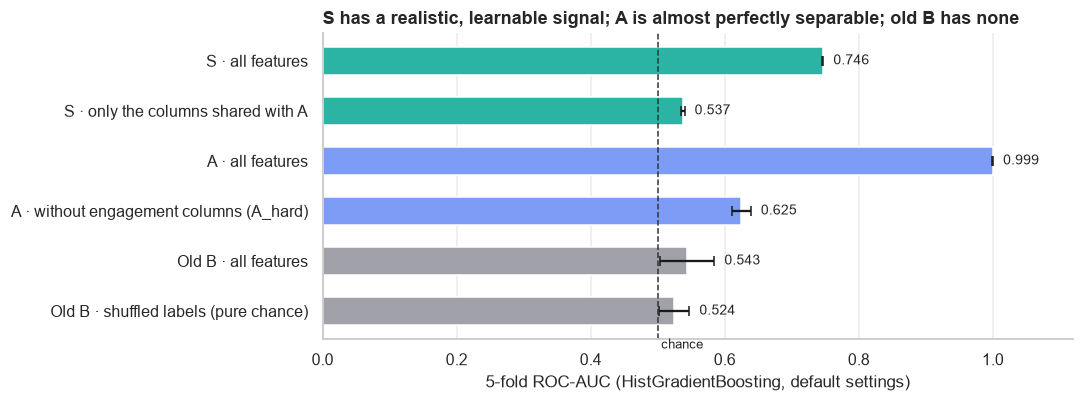

In [28]:
fig, ax = plt.subplots(figsize=(10, 3.8))
p = signal.iloc[::-1]
colors = [DS_COLORS["Old B"] if k.startswith("Old B") else DS_COLORS[k.split(" ")[0]] for k in p.index]
ax.barh(p.index, p["mean AUC"], xerr=p["std"], color=colors, height=0.55, capsize=3)
for y, (v, sd) in enumerate(zip(p["mean AUC"], p["std"])):
    ax.text(v + sd + 0.015, y, f"{v:.3f}", va="center", fontsize=9)
ax.axvline(0.5, color="#333", ls="--", lw=1)
ax.text(0.505, -0.75, "chance", fontsize=8.5)
ax.set_xlim(0, 1.12)
ax.set_xlabel("5-fold ROC-AUC (HistGradientBoosting, default settings)")
ax.set_title("S has a realistic, learnable signal; A is almost perfectly separable; old B has none")
ax.grid(axis="y", visible=False)
fig.tight_layout()
savefig(fig, "01_signal_check")
plt.show()

## 10. Key findings

**Data quality (all datasets)**
1. All three datasets are complete: **0 missing cells, 0 duplicate rows, 0 duplicate IDs**.
2. **Derived and redundant columns:**
   - S `total_charges` = `account_age × monthly_charges` (100% of rows).
   - A `avg_watch_time_per_day` = `watch_hours / (last_login_days + 1)` (100% of rows).
   - A `monthly_fee` duplicates `subscription_type`.
3. **Invalid values:** 10 rows in A claim more than 24 h of viewing per day. S has no out-of-range values.
4. **Outliers:** S has none. A's `watch_hours` has a plausible long tail (up to 110 h), so it is kept.

**Dataset S, the main modelling dataset**

5. **18.1% churn, so S is imbalanced.** Accuracy is misleading here: predicting "stays" for everyone scores 81.9%.
6. **Churn drivers are smooth and believable:**
   - Churn falls from about 33% (accounts under 6 months old) to about 8% (oldest accounts).
   - Churn falls as average session length and downloads increase.
   - Churn rises from about 12% to 25% as monthly charges increase from $5 to $20.
   - Median account age is 40 months for churners vs 65 for retained customers.
   - Median session length is 70 minutes for churners vs 98 for retained customers.
7. **Categorical columns barely matter** in S (every category is within about 2.5 points of 18.1%; Cramér's V < 0.04).
8. **Every S column was generated independently** (|ρ| < 0.01 between columns, apart from the derived
   `total_charges`). Each column still has its own link to churn.
9. **Learnable but not trivial:** gradient boosting reaches **ROC-AUC 0.746**, which leaves real room for
   model comparison, imbalance handling and threshold tuning.

**Dataset A, comparison and augmentation target**

10. Churn is driven by engagement. There is a sharp 30-day cliff (17–35% → 73–78%) and low watch hours for
    churners. Basic plan, Crypto and Gift Card payments churn more. Demographics carry no signal.
11. **Almost perfectly separable (AUC 0.999).** Without the 3 engagement columns, AUC drops to **0.625**.
    That gap is what the augmentation study tries to close.

**Old Dataset B: audit**

12. No feature relates to churn (all |ρ| < 0.06). A model scores **AUC 0.543 ± 0.041**, which is no better than
    shuffled labels (0.524 ± 0.023). **Old B is excluded.**

**Columns shared by A and S**

13. Only `subscription_type` matches cleanly. Device, genre and gender need mapping, payment methods barely
    overlap, and price means different things in the two datasets.
14. In S, the shared columns predict churn only weakly (**AUC 0.537**). Because S's columns are independent of
    each other, they are also unlikely to predict the behavioural columns we want to transfer.

---

### Implications for the next phases
* **Notebook 02, cleaning (Aayush):**
  - Drop `total_charges` (S), plus `monthly_fee` and `avg_watch_time_per_day` (A).
  - Convert Yes/No columns to 0/1.
  - Keep A's `watch_hours` tail and log-transform it for Logistic Regression.
* **Notebook 03, feature mapping (Sukhraj):**
  - Apply the mapping table in section 8.
  - Do not match on price.
  - Decide how to handle payment method and A's "Other" gender.
* **Notebook 04, augmentation study (Sukhraj):**
  - Run the transferability pre-check first: R² of each S behavioural column predicted from the shared columns.
  - Section 8 predicts R² ≈ 0. In that case, `A_hard_augmented` should score about the same as
    `A_hard_random`. That is still a valid, explainable result.
* **Notebook 05, modelling (Aayush):**
  - S is the headline result.
  - Use stratified splits, compare class weighting, tune the threshold, and report PR-AUC.